# Music Genre Classification using Mel-Spectrograms and Deep Learning

**Dataset:** GTZAN (1,000 tracks × 30s, 10 genres) | **Framework:** TensorFlow/Keras

**Pipeline:**
1. Load audio using librosa (SR = 22050 Hz), skip corrupted files
2. Split each 30s clip into 3s segments → mel-spectrograms (128 mel bands)
3. Track-level stratified split (70/15/15) — no data leakage
4. Four models: Custom CNN, VGG16, ResNet50, EfficientNet-B0
5. SpecAugment, label smoothing, ReduceLROnPlateau
6. Segment-level and track-level evaluation with confusion matrices
7. Save the best model for the Streamlit web app

## 1. Setup & Configuration

In [1]:
import os
import numpy as np
import librosa
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import json

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [2]:
DATASET_PATH = "/kaggle/input/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/Data/genres_original"
SAVE_DIR = "/kaggle/working/"
IMAGES_DIR = os.path.join(SAVE_DIR, "Images")
MODEL_DIR = os.path.join(SAVE_DIR, "Model")
os.makedirs(IMAGES_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

SR = 22050
DURATION = 30
SEGMENT_DURATION = 3
SAMPLES_PER_SEGMENT = SR * SEGMENT_DURATION
N_MELS = 128
HOP_LENGTH = 512
N_FFT = 2048
SEED = 42
EPOCHS = 50
BATCH_SIZE = 32
PATIENCE = 8

GENRES = sorted([
    g for g in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, g))
])
NUM_GENRES = len(GENRES)
GENRE_TO_IDX = {g: i for i, g in enumerate(GENRES)}
IDX_TO_GENRE = {i: g for g, i in GENRE_TO_IDX.items()}

CORRUPTED_FILES = {"jazz.00054.wav"}

np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"Genres found ({NUM_GENRES}): {GENRES}")

Genres found (10): ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


## 2. Load Audio & Extract Mel-Spectrograms

In [3]:
def extract_segments(file_path, sr=SR, n_mels=N_MELS, hop_length=HOP_LENGTH, n_fft=N_FFT):
    """Extract mel-spectrogram segments from a single audio file."""
    try:
        y, _ = librosa.load(file_path, sr=sr, duration=DURATION)
    except Exception as e:
        print(f"  Skipping {file_path}: {e}")
        return []

    segments = []
    num_segments = DURATION // SEGMENT_DURATION

    for s in range(num_segments):
        start = s * SAMPLES_PER_SEGMENT
        end = start + SAMPLES_PER_SEGMENT
        segment = y[start:end]

        if len(segment) < SAMPLES_PER_SEGMENT:
            continue

        mel = librosa.feature.melspectrogram(
            y=segment, sr=sr, n_mels=n_mels, n_fft=n_fft, hop_length=hop_length
        )
        mel_db = librosa.power_to_db(mel, ref=np.max)

        # Per-sample standardization (zero mean, unit variance)
        mean = mel_db.mean()
        std = mel_db.std()
        if std > 0:
            mel_db = (mel_db - mean) / std
        else:
            mel_db = mel_db - mean

        segments.append(mel_db)

    return segments

In [4]:
print("Loading dataset and extracting features...")

track_data = []

track_id = 0
for genre in GENRES:
    genre_dir = os.path.join(DATASET_PATH, genre)
    files = sorted([f for f in os.listdir(genre_dir) if f.endswith(".wav")])
    label = GENRE_TO_IDX[genre]

    for fname in files:
        if fname in CORRUPTED_FILES:
            print(f"  Skipping corrupted: {fname}")
            continue

        file_path = os.path.join(genre_dir, fname)
        segments = extract_segments(file_path)

        if segments:
            track_data.append({
                "track_id": track_id,
                "genre": genre,
                "label": label,
                "segments": segments,
                "filename": fname,
            })
            track_id += 1

print(f"Loaded {len(track_data)} tracks, total segments: {sum(len(t['segments']) for t in track_data)}")

Loading dataset and extracting features...
  Skipping corrupted: jazz.00054.wav
Loaded 999 tracks, total segments: 9981


## 3. Track-Level Stratified Split (70/15/15)

Split by **track** (not segment) to prevent data leakage. All 10 segments of a track stay in the same split.

In [5]:
track_ids = np.array([t["track_id"] for t in track_data])
track_labels = np.array([t["label"] for t in track_data])

train_ids, temp_ids, train_labels, temp_labels = train_test_split(
    track_ids, track_labels, test_size=0.30, stratify=track_labels, random_state=SEED
)
val_ids, test_ids, val_labels, test_labels = train_test_split(
    temp_ids, temp_labels, test_size=0.50, stratify=temp_labels, random_state=SEED
)

print(f"Track split — Train: {len(train_ids)}, Val: {len(val_ids)}, Test: {len(test_ids)}")

id_to_track = {t["track_id"]: t for t in track_data}


def build_arrays(ids):
    """Build X, y arrays from track IDs (segment-level)."""
    X, y, segment_track_ids = [], [], []
    for tid in ids:
        t = id_to_track[tid]
        for seg in t["segments"]:
            X.append(seg)
            y.append(t["label"])
            segment_track_ids.append(tid)
    X = np.array(X)[..., np.newaxis]  # (N, 128, T, 1)
    y = np.array(y)
    return X, y, np.array(segment_track_ids)


X_train, y_train, train_seg_tids = build_arrays(train_ids)
X_val, y_val, val_seg_tids = build_arrays(val_ids)
X_test, y_test, test_seg_tids = build_arrays(test_ids)

# Convert labels to one-hot for CategoricalCrossentropy (supports label smoothing)
y_train_oh = keras.utils.to_categorical(y_train, NUM_GENRES)
y_val_oh = keras.utils.to_categorical(y_val, NUM_GENRES)
y_test_oh = keras.utils.to_categorical(y_test, NUM_GENRES)

print(f"Segment split — Train: {X_train.shape[0]}, Val: {X_val.shape[0]}, Test: {X_test.shape[0]}")
print(f"Input shape: {X_train.shape[1:]}")

# Verify no track leakage
assert len(set(train_ids) & set(val_ids)) == 0, "Leakage: train & val share tracks!"
assert len(set(train_ids) & set(test_ids)) == 0, "Leakage: train & test share tracks!"
assert len(set(val_ids) & set(test_ids)) == 0, "Leakage: val & test share tracks!"
print("No data leakage detected.")

Track split — Train: 699, Val: 150, Test: 150
Segment split — Train: 6982, Val: 1500, Test: 1499
Input shape: (128, 130, 1)
No data leakage detected.


## 4. SpecAugment Data Augmentation

Frequency and time masking applied **only during training** to improve generalization.

In [6]:
class SpecAugment(layers.Layer):
    """XLA-compatible frequency and time masking (SpecAugment)."""
    def __init__(self, freq_mask_param=10, time_mask_param=10, n_masks=2, **kwargs):
        super().__init__(**kwargs)
        self.freq_mask_param = freq_mask_param
        self.time_mask_param = time_mask_param
        self.n_masks = n_masks

    def call(self, inputs, training=None):
        if not training:
            return inputs

        x = inputs
        freq_dim = tf.shape(x)[1]
        time_dim = tf.shape(x)[2]

        freq_range = tf.range(freq_dim)
        time_range = tf.range(time_dim)

        for _ in range(self.n_masks):
            # Frequency masking
            f = tf.random.uniform([], 1, self.freq_mask_param, dtype=tf.int32)
            f0 = tf.random.uniform([], 0, freq_dim - f, dtype=tf.int32)
            freq_mask = tf.cast(
                tf.logical_or(freq_range < f0, freq_range >= f0 + f), tf.float32
            )
            x = x * freq_mask[tf.newaxis, :, tf.newaxis, tf.newaxis]

            # Time masking
            t = tf.random.uniform([], 1, self.time_mask_param, dtype=tf.int32)
            t0 = tf.random.uniform([], 0, time_dim - t, dtype=tf.int32)
            time_mask = tf.cast(
                tf.logical_or(time_range < t0, time_range >= t0 + t), tf.float32
            )
            x = x * time_mask[tf.newaxis, tf.newaxis, :, tf.newaxis]

        return x

    def get_config(self):
        config = super().get_config()
        config.update({
            "freq_mask_param": self.freq_mask_param,
            "time_mask_param": self.time_mask_param,
            "n_masks": self.n_masks,
        })
        return config

## 5. Model Definitions

Four models:
1. **Custom CNN** — trained from scratch, 3 conv blocks (32 → 64 → 128)
2. **VGG16** — pretrained on ImageNet, fine-tuned
3. **ResNet50** — pretrained on ImageNet, fine-tuned
4. **EfficientNet-B0** — pretrained on ImageNet, fine-tuned

Transfer learning models use a 1×1 Conv2D to project 1-channel spectrograms to 3 channels.

In [7]:
input_shape = X_train.shape[1:]

def build_custom_cnn(input_shape, num_classes):
    inputs = layers.Input(shape=input_shape)
    x = SpecAugment(freq_mask_param=12, time_mask_param=8, n_masks=2)(inputs)

    for filters, drop in [(32, 0.25), (64, 0.3), (128, 0.35)]:
        x = layers.Conv2D(filters, (3, 3), padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.Conv2D(filters, (3, 3), padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D((2, 2))(x)
        x = layers.Dropout(drop)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(128)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs=inputs, outputs=outputs), None


def build_transfer_model(base_cls, input_shape, num_classes, dropout=0.3):
    inputs = layers.Input(shape=input_shape)
    x = SpecAugment(freq_mask_param=12, time_mask_param=8, n_masks=2)(inputs)
    x = layers.Conv2D(3, (1, 1), padding="same")(x)

    base = base_cls(weights="imagenet", include_top=False,
                    input_shape=(input_shape[0], input_shape[1], 3))
    x = base(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(128)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs=inputs, outputs=outputs), base


MODEL_CONFIGS = {
    "Custom_CNN": {
        "build_fn": lambda: build_custom_cnn(input_shape, NUM_GENRES),
        "lr": 1e-3, "head_epochs": 0,
    },
    "VGG16": {
        "build_fn": lambda: build_transfer_model(keras.applications.VGG16, input_shape, NUM_GENRES),
        "lr": 1e-4, "head_epochs": 3,
    },
    "ResNet50": {
        "build_fn": lambda: build_transfer_model(keras.applications.ResNet50, input_shape, NUM_GENRES),
        "lr": 1e-4, "head_epochs": 3,
    },
    "EfficientNet_B0": {
        "build_fn": lambda: build_transfer_model(keras.applications.EfficientNetB0, input_shape, NUM_GENRES),
        "lr": 3e-4, "head_epochs": 3,
    },
}

print(f"Input shape: {input_shape}")
print(f"Models to train: {list(MODEL_CONFIGS.keys())}")

Input shape: (128, 130, 1)
Models to train: ['Custom_CNN', 'VGG16', 'ResNet50', 'EfficientNet_B0']


## 6. Training & Evaluation Utilities

In [8]:
def train_model(name, config):
    print(f"\n{'='*60}")
    print(f"  Training: {name}")
    print(f"{'='*60}")

    tf.random.set_seed(SEED)
    np.random.seed(SEED)

    model, base = config["build_fn"]()
    lr = config["lr"]
    head_epochs = config["head_epochs"]
    loss_fn = keras.losses.CategoricalCrossentropy(label_smoothing=0.1)

    full_history = {"accuracy": [], "val_accuracy": [], "loss": [], "val_loss": []}

    # Phase 1: head-only warmup (transfer learning only)
    if base is not None and head_epochs > 0:
        base.trainable = False
        model.compile(optimizer=keras.optimizers.Adam(1e-3),
                      loss=loss_fn, metrics=["accuracy"])
        print(f"[{name}] Phase 1: Head-only ({head_epochs} epochs, lr=1e-3)")
        h1 = model.fit(X_train, y_train_oh, validation_data=(X_val, y_val_oh),
                       epochs=head_epochs, batch_size=BATCH_SIZE, verbose=1)
        for k in full_history:
            full_history[k].extend(h1.history[k])

    # Phase 2: full training / fine-tuning
    if base is not None:
        base.trainable = True

    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss=loss_fn, metrics=["accuracy"])

    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=PATIENCE,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=4, min_lr=1e-6, verbose=1),
    ]

    phase = "Fine-tuning" if base is not None else "Full training"
    print(f"[{name}] Phase 2: {phase} (up to {EPOCHS} epochs, lr={lr})")
    h2 = model.fit(X_train, y_train_oh, validation_data=(X_val, y_val_oh),
                   epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1)
    for k in full_history:
        full_history[k].extend(h2.history[k])

    return model, full_history


def evaluate_model(model, X, y, seg_tids, id_to_track):
    probs = model.predict(X, verbose=0)
    seg_pred = np.argmax(probs, axis=1)
    seg_acc = float(np.mean(seg_pred == y))

    unique_tids = np.unique(seg_tids)
    track_preds, track_trues = [], []
    for tid in unique_tids:
        mask = seg_tids == tid
        avg = probs[mask].mean(axis=0)
        track_preds.append(np.argmax(avg))
        track_trues.append(id_to_track[tid]["label"])

    track_preds = np.array(track_preds)
    track_trues = np.array(track_trues)
    track_acc = float(np.mean(track_preds == track_trues))

    return {"seg_acc": seg_acc, "track_acc": track_acc,
            "seg_pred": seg_pred, "probs": probs,
            "track_preds": track_preds, "track_trues": track_trues}

print("Training and evaluation functions defined.")

Training and evaluation functions defined.


## 7. Train All Four Models

In [9]:
trained_models = {}
histories = {}
results = {}

for name, config in MODEL_CONFIGS.items():
    model, history = train_model(name, config)
    res = evaluate_model(model, X_test, y_test, test_seg_tids, id_to_track)

    trained_models[name] = model
    histories[name] = history
    results[name] = res

    print(f"\n>> [{name}] Segment Acc: {res['seg_acc']:.4f} | Track Acc: {res['track_acc']:.4f}")

    # Save each model temporarily to free memory
    model.save(os.path.join(MODEL_DIR, f"temp_{name}.keras"))

print("\n" + "="*60)
print("All models trained!")
for n, r in results.items():
    print(f"  {n:20s}  Seg: {r['seg_acc']:.4f}  Track: {r['track_acc']:.4f}")


  Training: Custom_CNN


I0000 00:00:1792596142.488046     120 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792596142.492191     120 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[Custom_CNN] Phase 2: Full training (up to 50 epochs, lr=0.001)
Epoch 1/50


2026-10-21 15:22:35.567513: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-21 15:22:35.721102: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-21 15:22:37.171987: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-21 15:22:37.464806: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  2/219 ━━━━━━━━━━━━━━━━━━━━ 14s 69ms/step - accuracy: 0.1016 - loss: 3.1612   

...

219/219 ━━━━━━━━━━━━━━━━━━━━ 83s 217ms/step - accuracy: 0.2451 - loss: 2.1849 - val_accuracy: 0.2500 - val_loss: 2.0029
Epoch 2/3
219/219 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - accuracy: 0.2804 - loss: 2.0172 - val_accuracy: 0.3347 - val_loss: 1.9296
Epoch 3/3
219/219 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.3085 - loss: 1.9414 - val_accuracy: 0.3253 - val_loss: 1.8887
[EfficientNet_B0] Phase 2: Fine-tuning (up to 50 epochs, lr=0.0003)
Epoch 1/50
218/219 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.3755 - loss: 1.8668

2026-10-21 16:26:07.544404: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-21 16:26:07.679508: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


219/219 ━━━━━━━━━━━━━━━━━━━━ 134s 294ms/step - accuracy: 0.4681 - loss: 1.6704 - val_accuracy: 0.1327 - val_loss: 2.5244 - learning_rate: 3.0000e-04
Epoch 2/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 13s 58ms/step - accuracy: 0.6669 - loss: 1.2872 - val_accuracy: 0.2073 - val_loss: 2.2161 - learning_rate: 3.0000e-04
Epoch 3/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 13s 59ms/step - accuracy: 0.7578 - loss: 1.0987 - val_accuracy: 0.2047 - val_loss: 2.5970 - learning_rate: 3.0000e-04
Epoch 4/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 12s 56ms/step - accuracy: 0.8124 - loss: 0.9746 - val_accuracy: 0.2067 - val_loss: 2.8126 - learning_rate: 3.0000e-04
Epoch 5/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 12s 56ms/step - accuracy: 0.8492 - loss: 0.8882 - val_accuracy: 0.6373 - val_loss: 1.3479 - learning_rate: 3.0000e-04
Epoch 6/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accuracy: 0.8886 - loss: 0.8109 - val_accuracy: 0.4367 - val_loss: 1.9988 - learning_rate: 3.0000e-04
Epoch 7/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accur

2026-10-21 16:37:08.591346: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-21 16:37:08.725650: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-21 16:37:09.059455: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-21 16:37:09.203834: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-21 16:37:10.049339: E external/local_xla/xla/stream_


>> [EfficientNet_B0] Segment Acc: 0.8205 | Track Acc: 0.8867

All models trained!
  Custom_CNN            Seg: 0.6491  Track: 0.7067
  VGG16                 Seg: 0.8459  Track: 0.8867
  ResNet50              Seg: 0.8266  Track: 0.8933
  EfficientNet_B0       Seg: 0.8205  Track: 0.8867


## 8. Training Curves

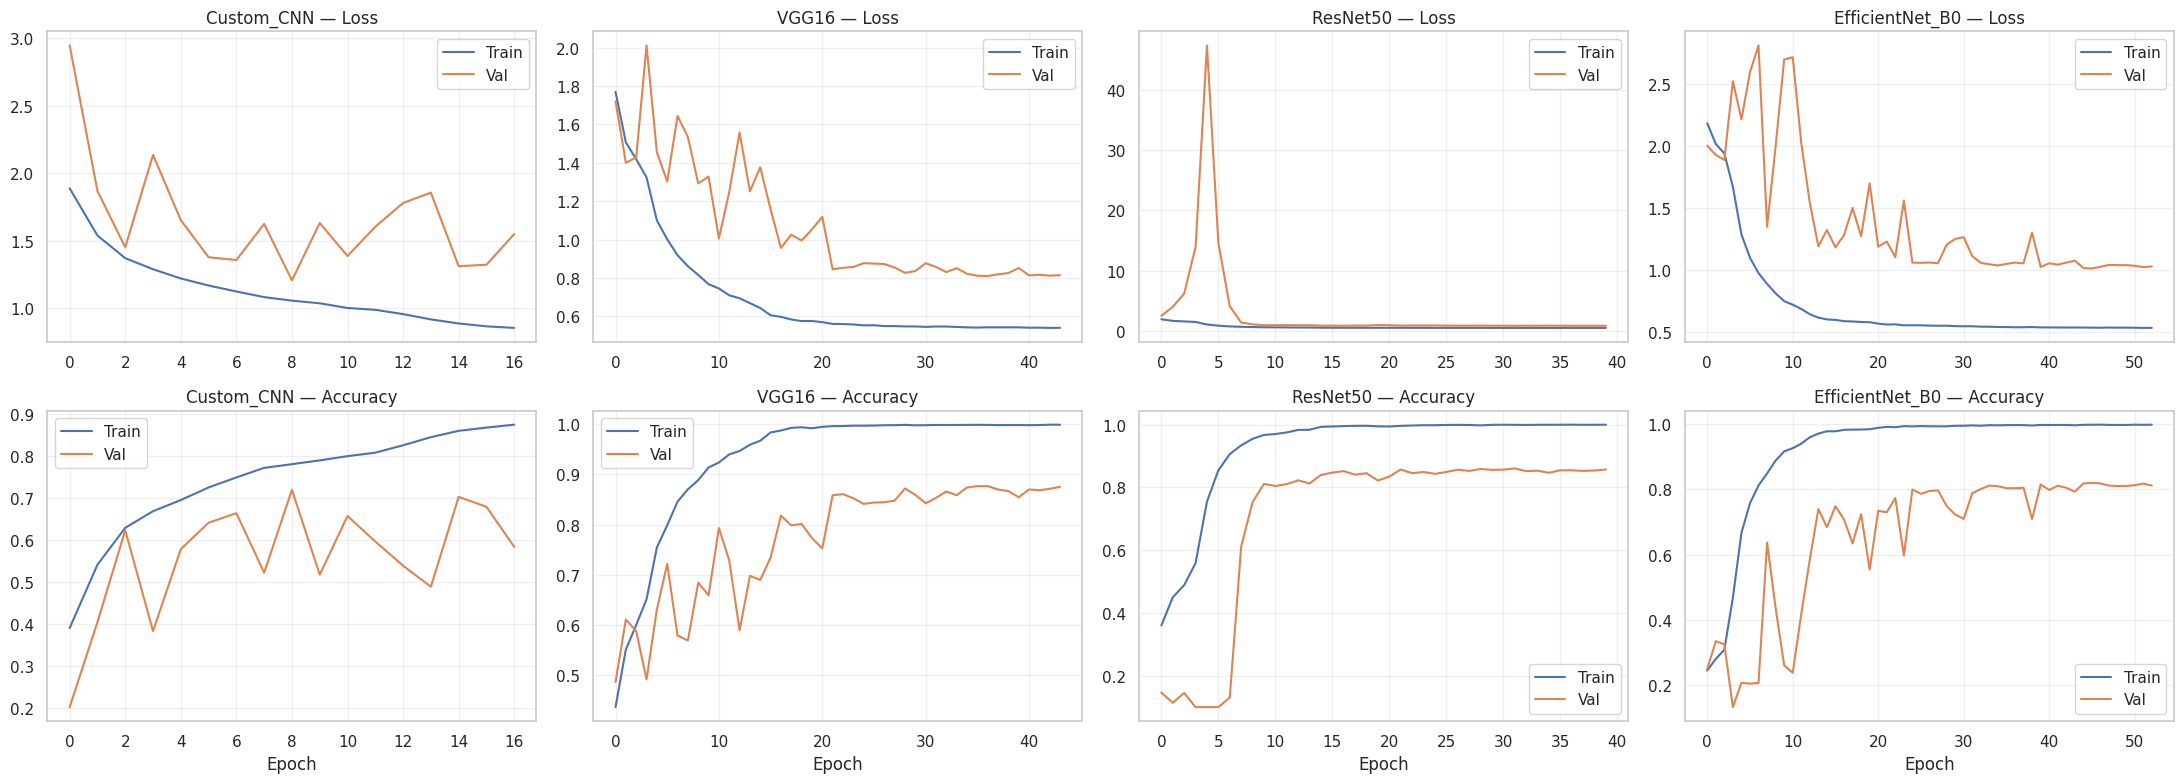

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(22, 8))
for j, (name, hist) in enumerate(histories.items()):
    axes[0, j].plot(hist["loss"], label="Train")
    axes[0, j].plot(hist["val_loss"], label="Val")
    axes[0, j].set_title(f"{name} — Loss")
    axes[0, j].legend()
    axes[0, j].grid(True, alpha=0.3)

    axes[1, j].plot(hist["accuracy"], label="Train")
    axes[1, j].plot(hist["val_accuracy"], label="Val")
    axes[1, j].set_title(f"{name} — Accuracy")
    axes[1, j].set_xlabel("Epoch")
    axes[1, j].legend()
    axes[1, j].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "training_curves.png"), dpi=130)
plt.show()

## 9. Model Comparison

Model                   Seg Acc  Track Acc
------------------------------------------
Custom_CNN               0.6491     0.7067
VGG16                    0.8459     0.8867
ResNet50                 0.8266     0.8933
EfficientNet_B0          0.8205     0.8867


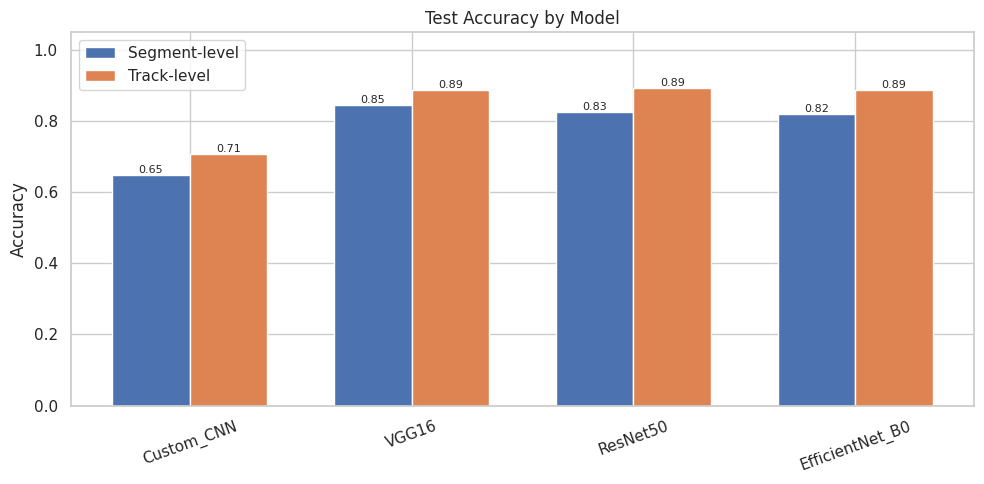

In [11]:
print(f"{'Model':<20} {'Seg Acc':>10} {'Track Acc':>10}")
print("-" * 42)
for name, res in results.items():
    print(f"{name:<20} {res['seg_acc']:>10.4f} {res['track_acc']:>10.4f}")

fig, ax = plt.subplots(figsize=(10, 5))
model_names = list(results.keys())
seg_accs = [results[n]["seg_acc"] for n in model_names]
track_accs = [results[n]["track_acc"] for n in model_names]

x = np.arange(len(model_names))
width = 0.35
bars1 = ax.bar(x - width/2, seg_accs, width, label="Segment-level")
bars2 = ax.bar(x + width/2, track_accs, width, label="Track-level")
ax.set_ylabel("Accuracy")
ax.set_title("Test Accuracy by Model")
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=20)
ax.set_ylim(0, 1.05)
ax.legend()
for bars in [bars1, bars2]:
    ax.bar_label(bars, fmt="%.2f", fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "model_comparison_accuracy.png"), dpi=150)
plt.show()

## 10. Confusion Matrices (Track-Level, All Models)

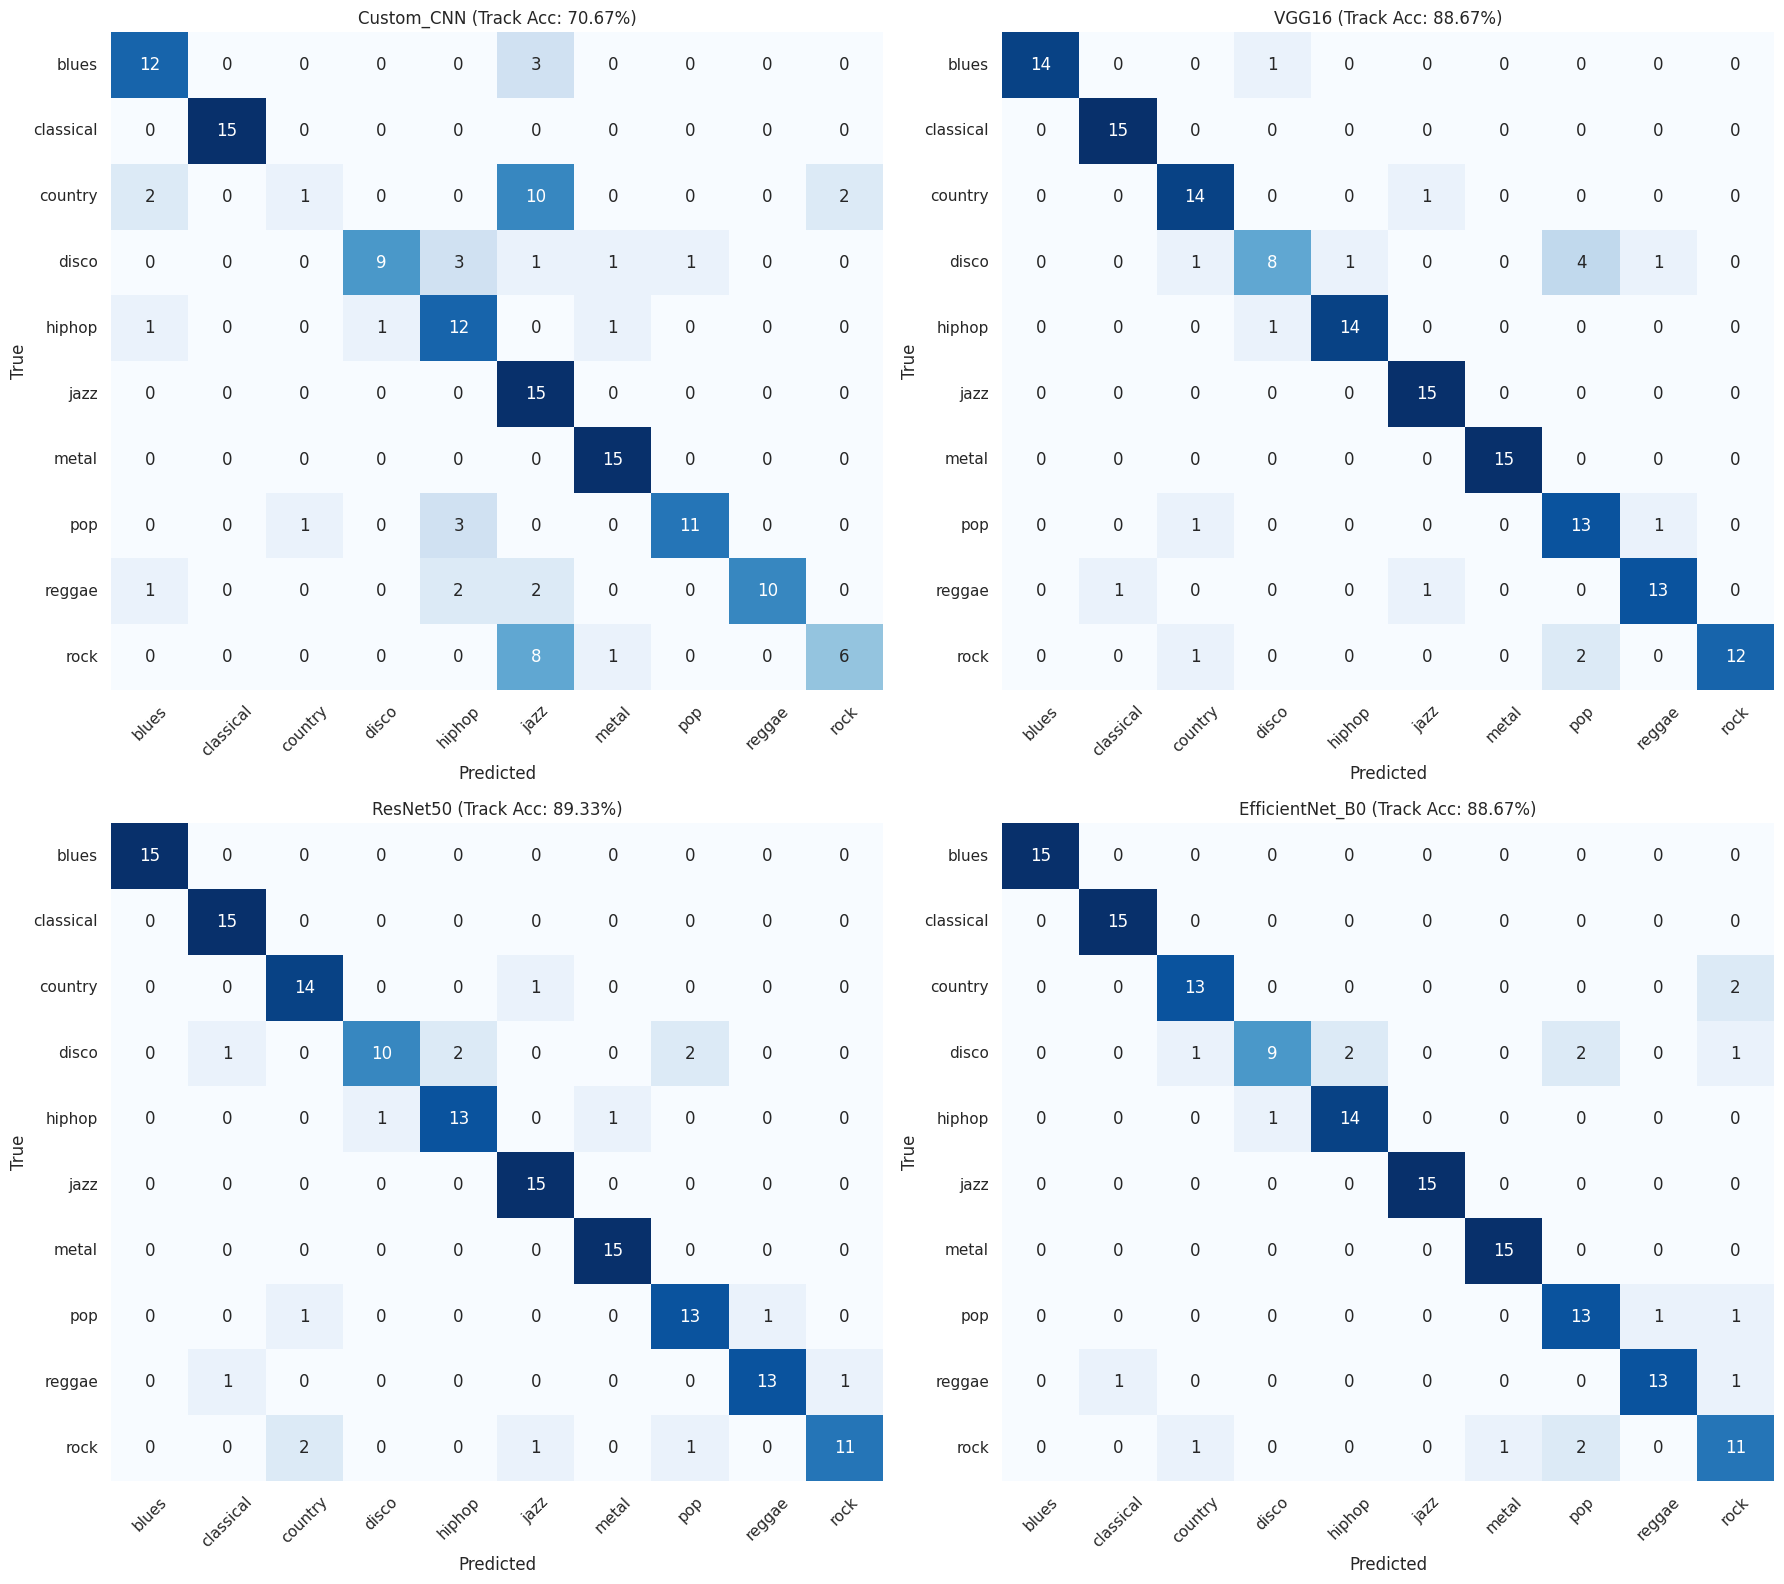

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(18, 16))
for ax, (name, res) in zip(axes.ravel(), results.items()):
    cm = confusion_matrix(res["track_trues"], res["track_preds"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=GENRES, yticklabels=GENRES, cbar=False, ax=ax)
    ax.set_title(f"{name} (Track Acc: {res['track_acc']:.2%})")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "confusion_matrices_all_models.png"), dpi=130)
plt.show()

## 11. Best Model — Detailed Analysis

Best model: ResNet50 (Track Accuracy: 0.8933)

--- Track-Level Classification Report ---
              precision    recall  f1-score   support

       blues       1.00      1.00      1.00        15
   classical       0.88      1.00      0.94        15
     country       0.82      0.93      0.88        15
       disco       0.91      0.67      0.77        15
      hiphop       0.87      0.87      0.87        15
        jazz       0.88      1.00      0.94        15
       metal       0.94      1.00      0.97        15
         pop       0.81      0.87      0.84        15
      reggae       0.93      0.87      0.90        15
        rock       0.92      0.73      0.81        15

    accuracy                           0.89       150
   macro avg       0.90      0.89      0.89       150
weighted avg       0.90      0.89      0.89       150



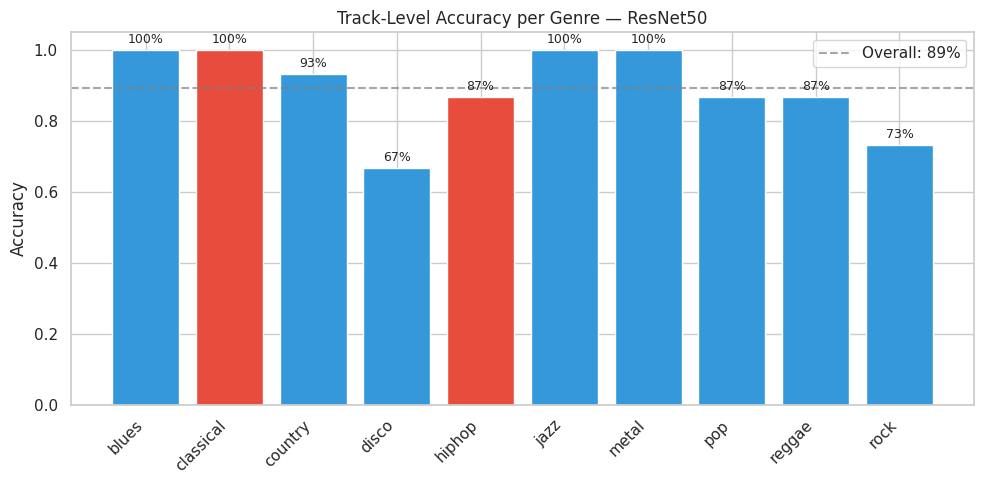

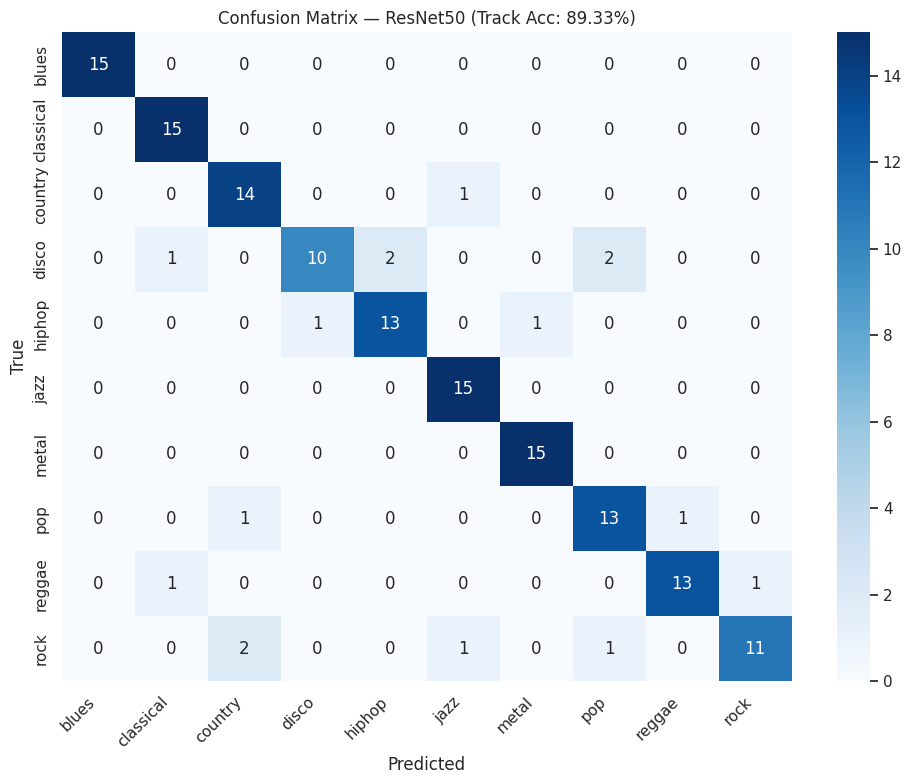

In [13]:
best_name = max(results, key=lambda n: results[n]["track_acc"])
best_res = results[best_name]

print(f"Best model: {best_name} (Track Accuracy: {best_res['track_acc']:.4f})\n")
print("--- Track-Level Classification Report ---")
print(classification_report(best_res["track_trues"], best_res["track_preds"], target_names=GENRES))

# Per-genre accuracy
per_genre_acc = {}
for i, genre in enumerate(GENRES):
    mask = best_res["track_trues"] == i
    if mask.sum() > 0:
        per_genre_acc[genre] = np.mean(best_res["track_preds"][mask] == i)

plt.figure(figsize=(10, 5))
colors = ["#e74c3c" if g in ("hiphop", "classical") else "#3498db" for g in per_genre_acc.keys()]
bars = plt.bar(per_genre_acc.keys(), per_genre_acc.values(), color=colors)
plt.title(f"Track-Level Accuracy per Genre — {best_name}")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
for bar, acc in zip(bars, per_genre_acc.values()):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
             f"{acc:.0%}", ha="center", fontsize=9)
plt.axhline(y=best_res["track_acc"], color="gray", linestyle="--", alpha=0.7,
            label=f"Overall: {best_res['track_acc']:.0%}")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "per_genre_accuracy.png"), dpi=150)
plt.show()

# Standalone confusion matrix for best model
plt.figure(figsize=(10, 8))
cm = confusion_matrix(best_res["track_trues"], best_res["track_preds"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=GENRES, yticklabels=GENRES)
plt.title(f"Confusion Matrix — {best_name} (Track Acc: {best_res['track_acc']:.2%})")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "confusion_matrix_best.png"), dpi=150)
plt.show()

## 12. Save Best Model & Metadata

In [14]:
best_model = trained_models[best_name]
best_model.save(os.path.join(MODEL_DIR, "genre_classifier.keras"))

metadata = {
    "genres": GENRES,
    "genre_to_idx": GENRE_TO_IDX,
    "sr": SR,
    "n_mels": N_MELS,
    "hop_length": HOP_LENGTH,
    "n_fft": N_FFT,
    "segment_duration": SEGMENT_DURATION,
    "input_shape": list(input_shape),
    "best_model": best_name,
    "segment_test_accuracy": best_res["seg_acc"],
    "track_test_accuracy": best_res["track_acc"],
    "all_results": {n: {"seg_acc": r["seg_acc"], "track_acc": r["track_acc"]}
                    for n, r in results.items()},
}
with open(os.path.join(MODEL_DIR, "model_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

print(f"Best model ({best_name}) saved to {MODEL_DIR}/genre_classifier.keras")
print(f"Metadata saved to {MODEL_DIR}/model_metadata.json")
print(f"Plots saved to {IMAGES_DIR}/")
print(f"\nFinal Results:")
for n, r in results.items():
    marker = " << BEST" if n == best_name else ""
    print(f"  {n:20s}  Seg: {r['seg_acc']:.4f}  Track: {r['track_acc']:.4f}{marker}")
print("\nDone!")

Best model (ResNet50) saved to /kaggle/working/Model/genre_classifier.keras
Metadata saved to /kaggle/working/Model/model_metadata.json
Plots saved to /kaggle/working/Images/

Final Results:
  Custom_CNN            Seg: 0.6491  Track: 0.7067
  VGG16                 Seg: 0.8459  Track: 0.8867
  ResNet50              Seg: 0.8266  Track: 0.8933 << BEST
  EfficientNet_B0       Seg: 0.8205  Track: 0.8867

Done!
